# SAHI: YOLO26 training and sliced inference

This notebook trains a YOLO26n detector on this workspace's train/validation splits, evaluates it on the held-out test split, and demonstrates SAHI sliced inference on a test image. SAHI is used here for inference-time slicing; model training itself is performed by Ultralytics YOLO. The test split is never used for training.

In [22]:
%pip install ultralytics sahi

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Run SAHI sliced inference

This cell uses the existing `baseline2.0` best checkpoint; it does not train a model. It runs sliced inference on the first test image and saves a visualization under `runs/detect/baseline2.0_sahi`. Run this cell directly (after installing the notebook dependencies if needed).

Image: 0000125_00084_d_0000122__1200_0_png.rf.79a12fe89420193c526c55ba1b96029f.jpg
False positives use class-aware matching at IoU >= 0.50; duplicate boxes count as false positives.
Baseline detections: 11 (TP=8, FP=3)
SAHI detections: 17 (TP=9, FP=8)
Baseline visualization: d:\AI-TOD.v2i.yolo26\runs\detect\baseline2.0_sahi\baseline\0000125_00084_d_0000122__1200_0_png.rf.79a12fe89420193c526c55ba1b96029f.jpg
SAHI visualization: d:\AI-TOD.v2i.yolo26\runs\detect\baseline2.0_sahi\sahi\prediction_visual.png


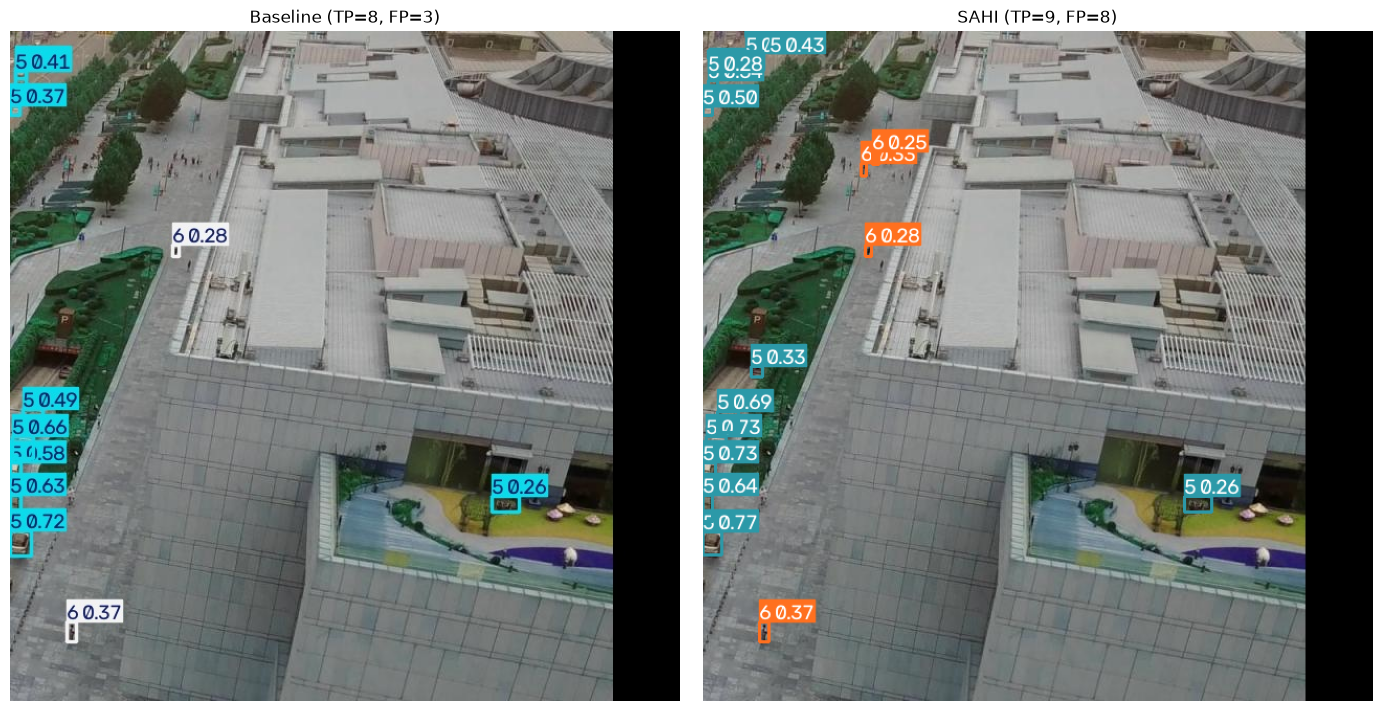

In [24]:
from pathlib import Path
import torch
import matplotlib.pyplot as plt
from ultralytics import YOLO
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction

ROOT = Path.cwd()
if not (ROOT / "runs").is_dir():
    ROOT = ROOT.parent

model_path = ROOT / "runs" / "detect" / "baseline2.0" / "weights" / "best.pt"
test_dir = ROOT / "datasets" / "baseline2.0" / "test" / "images"
if not model_path.is_file():
    raise FileNotFoundError(f"Baseline checkpoint not found: {model_path}")
if not test_dir.is_dir():
    raise FileNotFoundError(f"Test image directory not found: {test_dir}")

test_images = sorted(p for p in test_dir.iterdir() if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"})
if not test_images:
    raise FileNotFoundError(f"No test images found in {test_dir}")

sample_image = test_images[5]
device = "cuda:0" if torch.cuda.is_available() else "cpu"

baseline_model = YOLO(str(model_path))
baseline_result = baseline_model.predict(
    source=str(sample_image),
    imgsz=640,
    conf=0.25,
    device=device,
    verbose=False,
)[0]

detection_model = AutoDetectionModel.from_pretrained(
    model_type="ultralytics",
    model_path=str(model_path),
    confidence_threshold=0.25,
    device=device,
    image_size=640,
)
sahi_result = get_sliced_prediction(
    str(sample_image),
    detection_model,
    slice_height=320,
    slice_width=320,
    overlap_height_ratio=0.25,
    overlap_width_ratio=0.25,
    postprocess_type="NMS",
    postprocess_match_threshold=0.5,
    verbose=0,
)

output_dir = ROOT / "runs" / "detect" / "baseline2.0_sahi"
baseline_output_dir = output_dir / "baseline"
sahi_output_dir = output_dir / "sahi"
baseline_output_dir.mkdir(parents=True, exist_ok=True)
sahi_output_dir.mkdir(parents=True, exist_ok=True)
baseline_visual_path = baseline_output_dir / sample_image.name
baseline_result.save(filename=str(baseline_visual_path))
sahi_result.export_visuals(export_dir=str(sahi_output_dir))
sahi_visual_path = sahi_output_dir / "prediction_visual.png"
if not sahi_visual_path.is_file():
    raise FileNotFoundError(f"SAHI visualization was not created: {sahi_visual_path}")

from PIL import Image

label_path = ROOT / "datasets" / "baseline2.0" / "test" / "labels" / f"{sample_image.stem}.txt"
if not label_path.is_file():
    raise FileNotFoundError(f"Test label not found: {label_path}")
with Image.open(sample_image) as image:
    image_width, image_height = image.size

ground_truth_boxes = []
for line in label_path.read_text(encoding="utf-8").splitlines():
    fields = line.split()
    if not fields:
        continue
    class_id = int(fields[0])
    x_center, y_center, box_width, box_height = map(float, fields[1:5])
    ground_truth_boxes.append((class_id, [
        (x_center - box_width / 2) * image_width,
        (y_center - box_height / 2) * image_height,
        (x_center + box_width / 2) * image_width,
        (y_center + box_height / 2) * image_height,
    ]))

baseline_predictions = [
    (int(class_id), float(score), box.tolist())
    for box, score, class_id in zip(
        baseline_result.boxes.xyxy.cpu().numpy(),
        baseline_result.boxes.conf.cpu().numpy(),
        baseline_result.boxes.cls.cpu().numpy(),
    )
]
sahi_predictions = [
    (int(detection.category.id), float(detection.score.value), detection.bbox.to_xyxy())
    for detection in sahi_result.object_prediction_list
]

def count_false_positives(predictions, targets, iou_threshold=0.5):
    matched_targets = set()
    for class_id, _, box in sorted(predictions, key=lambda prediction: prediction[1], reverse=True):
        best_target = None
        best_iou = 0.0
        for target_index, (target_class, target_box) in enumerate(targets):
            if target_class != class_id or target_index in matched_targets:
                continue
            x1 = max(box[0], target_box[0])
            y1 = max(box[1], target_box[1])
            x2 = min(box[2], target_box[2])
            y2 = min(box[3], target_box[3])
            intersection = max(0.0, x2 - x1) * max(0.0, y2 - y1)
            pred_area = max(0.0, box[2] - box[0]) * max(0.0, box[3] - box[1])
            target_area = max(0.0, target_box[2] - target_box[0]) * max(0.0, target_box[3] - target_box[1])
            iou = intersection / max(pred_area + target_area - intersection, 1e-12)
            if iou > best_iou:
                best_iou = iou
                best_target = target_index
        if best_target is not None and best_iou >= iou_threshold:
            matched_targets.add(best_target)
    true_positives = len(matched_targets)
    return len(predictions) - true_positives, true_positives

baseline_false_positives, baseline_true_positives = count_false_positives(baseline_predictions, ground_truth_boxes)
sahi_false_positives, sahi_true_positives = count_false_positives(sahi_predictions, ground_truth_boxes)
print(f"Image: {sample_image.name}")
print("False positives use class-aware matching at IoU >= 0.50; duplicate boxes count as false positives.")
print(f"Baseline detections: {len(baseline_predictions)} (TP={baseline_true_positives}, FP={baseline_false_positives})")
print(f"SAHI detections: {len(sahi_predictions)} (TP={sahi_true_positives}, FP={sahi_false_positives})")
print(f"Baseline visualization: {baseline_visual_path}")
print(f"SAHI visualization: {sahi_visual_path}")

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(plt.imread(baseline_visual_path))
axes[0].set_title(f"Baseline (TP={baseline_true_positives}, FP={baseline_false_positives})")
axes[0].axis("off")
axes[1].imshow(plt.imread(sahi_visual_path))
axes[1].set_title(f"SAHI (TP={sahi_true_positives}, FP={sahi_false_positives})")
axes[1].axis("off")
plt.tight_layout()
plt.show()


## Compare baseline2.0 and SAHI on the full test split

This compares full-image baseline predictions with SAHI using 320x320 tiles (25% overlap) plus a standard full-image pass. Both methods use the same test labels, confidence threshold, and IoU matching. It uses the existing checkpoint and does not train.

In [19]:
from pathlib import Path
import numpy as np
import torch
from PIL import Image
from tqdm.auto import tqdm
from ultralytics import YOLO
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction

ROOT = Path.cwd()
model_path = ROOT / "runs" / "detect" / "baseline2.0" / "weights" / "best.pt"
if not model_path.is_file() and (ROOT.parent / "runs" / "detect" / "baseline2.0" / "weights" / "best.pt").is_file():
    ROOT = ROOT.parent
    model_path = ROOT / "runs" / "detect" / "baseline2.0" / "weights" / "best.pt"
test_dir = ROOT / "datasets" / "baseline2.0" / "test" / "images"
label_dir = ROOT / "datasets" / "baseline2.0" / "test" / "labels"
if not model_path.is_file():
    raise FileNotFoundError(f"Baseline checkpoint not found: {model_path}")
if not test_dir.is_dir() or not label_dir.is_dir():
    raise FileNotFoundError(f"Test images or labels directory not found under {test_dir.parent}")

image_paths = sorted(p for p in test_dir.iterdir() if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"})
if not image_paths:
    raise FileNotFoundError(f"No test images found in {test_dir}")

# Load ground-truth boxes in pixel xyxy format.
ground_truth = []
for image_path in image_paths:
    label_path = label_dir / f"{image_path.stem}.txt"
    if not label_path.is_file():
        raise FileNotFoundError(f"Missing test label: {label_path}")
    with Image.open(image_path) as image:
        width, height = image.size
    boxes_by_class = {class_id: [] for class_id in range(3)}
    for line in label_path.read_text(encoding="utf-8").splitlines():
        fields = line.split()
        if not fields:
            continue
        class_id = int(fields[0])
        if class_id not in boxes_by_class:
            raise ValueError(f"Unexpected class {class_id} in {label_path}")
        x_center, y_center, box_width, box_height = map(float, fields[1:5])
        boxes_by_class[class_id].append([
            (x_center - box_width / 2) * width,
            (y_center - box_height / 2) * height,
            (x_center + box_width / 2) * width,
            (y_center + box_height / 2) * height,
        ])
    ground_truth.append({k: np.asarray(v, dtype=float).reshape(-1, 4) for k, v in boxes_by_class.items()})

device = "cuda:0" if torch.cuda.is_available() else "cpu"
baseline_model = YOLO(str(model_path))
sahi_model = AutoDetectionModel.from_pretrained(
    model_type="ultralytics",
    model_path=str(model_path),
    confidence_threshold=0.001,
    device=device,
    image_size=640,
)
predictions = {"Baseline2.0": [], "Baseline2.0 + SAHI": []}

for image_index, image_path in enumerate(tqdm(image_paths, desc="Evaluating test images")):
    baseline_result = baseline_model.predict(
        source=str(image_path), imgsz=640, conf=0.001, max_det=1499, device=device, verbose=False
    )[0]
    if baseline_result.boxes is not None:
        for box, score, class_id in zip(
            baseline_result.boxes.xyxy.cpu().numpy(),
            baseline_result.boxes.conf.cpu().numpy(),
            baseline_result.boxes.cls.cpu().numpy().astype(int),
        ):
            predictions["Baseline2.0"].append((image_index, class_id, float(score), box))

    sliced_result = get_sliced_prediction(
        str(image_path),
        sahi_model,
        slice_height=320,
        slice_width=320,
        overlap_height_ratio=0.25,
        overlap_width_ratio=0.25,
        perform_standard_pred=True,
        postprocess_type="NMS",
        postprocess_match_threshold=0.65,
        verbose=0,
    )
    for detection in sliced_result.object_prediction_list:
        predictions["Baseline2.0 + SAHI"].append((
            image_index,
            int(detection.category.id),
            float(detection.score.value),
            np.asarray(detection.bbox.to_xyxy(), dtype=float),
        ))

def box_iou(box, boxes):
    if len(boxes) == 0:
        return np.zeros(0, dtype=float)
    x1 = np.maximum(box[0], boxes[:, 0])
    y1 = np.maximum(box[1], boxes[:, 1])
    x2 = np.minimum(box[2], boxes[:, 2])
    y2 = np.minimum(box[3], boxes[:, 3])
    intersection = np.maximum(0, x2 - x1) * np.maximum(0, y2 - y1)
    area_box = max(0, box[2] - box[0]) * max(0, box[3] - box[1])
    area_boxes = np.maximum(0, boxes[:, 2] - boxes[:, 0]) * np.maximum(0, boxes[:, 3] - boxes[:, 1])
    return intersection / np.maximum(area_box + area_boxes - intersection, 1e-12)

def match_at_iou(rows, class_id, iou_threshold, confidence_threshold=0.001):
    class_rows = sorted(
        (row for row in rows if row[1] == class_id and row[2] >= confidence_threshold),
        key=lambda row: row[2], reverse=True
    )
    matched = set()
    true_positive = np.zeros(len(class_rows), dtype=float)
    false_positive = np.zeros(len(class_rows), dtype=float)
    for index, (image_index, _, _, box) in enumerate(class_rows):
        gt_boxes = ground_truth[image_index][class_id]
        ious = box_iou(box, gt_boxes)
        for gt_index in np.argsort(ious)[::-1]:
            if ious[gt_index] < iou_threshold:
                break
            key = (image_index, int(gt_index))
            if key not in matched:
                matched.add(key)
                true_positive[index] = 1
                break
        if true_positive[index] == 0:
            false_positive[index] = 1
    return class_rows, true_positive, false_positive

def average_precision(recall, precision):
    return np.mean([
        np.max(precision[recall >= threshold]) if np.any(recall >= threshold) else 0.0
        for threshold in np.linspace(0, 1, 101)
    ])

class_names = ["3", "5", "6"]
iou_thresholds = np.arange(0.50, 0.96, 0.05)
results = {}
for method, rows in predictions.items():
    class_metrics = {}
    for class_id, class_name in enumerate(class_names):
        target_count = sum(len(gt[class_id]) for gt in ground_truth)
        ap_values = []
        for iou_threshold in iou_thresholds:
            class_rows, tp, fp = match_at_iou(rows, class_id, float(iou_threshold))
            cumulative_tp = np.cumsum(tp)
            cumulative_fp = np.cumsum(fp)
            recall_curve = cumulative_tp / max(target_count, 1)
            precision_curve = cumulative_tp / np.maximum(cumulative_tp + cumulative_fp, 1e-12)
            ap_values.append(average_precision(recall_curve, precision_curve) if target_count else 0.0)
        _, tp50, fp50 = match_at_iou(rows, class_id, 0.50, confidence_threshold=0.25)
        class_tp = int(tp50.sum())
        class_fp = int(fp50.sum())
        class_metrics[class_name] = {
            "precision": class_tp / max(class_tp + class_fp, 1),
            "recall": class_tp / max(target_count, 1),
            "map50": ap_values[0],
            "map50_95": float(np.mean(ap_values)),
            "tp": class_tp,
            "fp": class_fp,
            "targets": target_count,
        }
    total_tp = sum(m["tp"] for m in class_metrics.values())
    total_fp = sum(m["fp"] for m in class_metrics.values())
    total_targets = sum(m["targets"] for m in class_metrics.values())
    results[method] = {
        "precision": total_tp / max(total_tp + total_fp, 1),
        "recall": total_tp / max(total_targets, 1),
        "map50": float(np.mean([m["map50"] for m in class_metrics.values()])),
        "map50_95": float(np.mean([m["map50_95"] for m in class_metrics.values()])),
        "classes": class_metrics,
    }

print()
print("Overall test metrics (P/R at conf=0.25; mAP uses confidence-ranked predictions):")
print(f"{'Method':<22} {'Precision':>10} {'Recall':>10} {'mAP50':>10} {'mAP50-95':>10}")
for method, metrics in results.items():
    print(f"{method:<22} {metrics['precision']:>10.3f} {metrics['recall']:>10.3f} {metrics['map50']:>10.3f} {metrics['map50_95']:>10.3f}")
    for class_name, class_metrics in metrics["classes"].items():
        print(f"  class {class_name}: P={class_metrics['precision']:.3f}, R={class_metrics['recall']:.3f}, mAP50={class_metrics['map50']:.3f}, mAP50-95={class_metrics['map50_95']:.3f}")


Evaluating test images: 100%|██████████| 300/300 [07:32<00:00,  1.51s/it]



Overall test metrics (P/R at conf=0.25; mAP uses confidence-ranked predictions):
Method                  Precision     Recall      mAP50   mAP50-95
Baseline2.0                 0.688      0.498      0.459      0.153
  class 3: P=0.596, R=0.505, mAP50=0.490, mAP50-95=0.184
  class 5: P=0.701, R=0.542, mAP50=0.582, mAP50-95=0.195
  class 6: P=0.660, R=0.213, mAP50=0.306, mAP50-95=0.081
Baseline2.0 + SAHI          0.677      0.558      0.460      0.153
  class 3: P=0.451, R=0.539, mAP50=0.443, mAP50-95=0.173
  class 5: P=0.712, R=0.612, mAP50=0.628, mAP50-95=0.212
  class 6: P=0.644, R=0.224, mAP50=0.309, mAP50-95=0.075
